# Draft: what does $\rho$ do over many treatment cycles?

We use the dimensionless model from `02-optimal-control-proper-time.ipynb`. Time $\hat t$ is measured in **adaptation times**, the relaxation time of the $A,B$ system:

$$\dot A = \tau_r(q)\,q\,(1-B), \qquad \dot B = \tau_r(q)\,(uA-B), \qquad \frac{d}{d\hat t}\log C = \rho\,\big[1-\alpha f(1-B)\big]$$

with $A(0)=B(0)=1$, $u\in\{u_{\min}, 1\}$ and $f(x)=x^+$ (B is a survival signal, as in figure 4).

| | definition | meaning | legend label |
|---|---|---|---|
| $\rho$ | $\dfrac{\tau_r(q)\,c_1}{b_2} = \dfrac{T_{\text{adapt}}}{T_{\text{tumor}}}$ | tumor growth (e-folds) during one adaptation time | *tumor growth per adaptation time* |
| $\alpha$ | $\dfrac{c_2\mu^k}{c_1}$ | max B-dependent kill rate / baseline growth rate | *tumor dependence on B* |
| $u_{\min}$ | | how strongly the drug blocks B production | *drug strength* |

Large $\rho$: the tumor is fast and adaptation is slow. Small $\rho$: adaptation is fast compared with the tumor (timescale separation).

**Key identity.** $A$ and $B$ do not depend on $\rho$ or $\alpha$. With $F(\hat t) = \int_0^{\hat t} f(1-B)\,ds$ (cumulative suppression):

$$\log\frac{C(\hat t)}{C(0)} = \rho\,\big[\hat t - \alpha F(\hat t)\big]$$

So we simulate $A,B,F$ once per schedule and get $\log C$ for every $(\rho,\alpha)$ for free.

**Questions for this draft**
1. In adaptation time, $\rho$ is a pure gain. What does it look like when the horizon is fixed in *tumor* time instead (e.g., a fixed number of tumor doublings)?
2. How do reset cycling and constant therapy compare as $\rho$ varies?
3. How much does the tumor rebound within each cycle as $\rho$ varies?

In [8]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp

sys.path.insert(0, '../src')
from rpa_control.style import set_style

set_style()
plt.rcParams['text.usetex'] = False

# ── Parameters ───────────────────────────────────────────────────────────
# Figure 4 uses a1=1, b1=1, b2=2, c1=0.05, c2=1, mu=1, b1_on=b1/2. In dimensionless form:
#   q = a1*b1/b2^2 = 0.25,  tau_r = 2  ->  1 adaptation time = tau_r/b2 = 1 time unit,
#   rho = tau_r*c1/b2 = 0.05,  alpha = c2*mu/c1 = 20,  u_min = 0.5
q     = 0.25
u_min = 0.5
u_max = 1.0
alpha = 20.0
rho_fig4 = 0.05

ON_COLOR    = 'lightgray'
RESET_COLOR = 'C0'
CONST_COLOR = '#8C8C8C'

In [9]:
# ── Model ────────────────────────────────────────────────────────────────

def t_relax(q):
    # relaxation time of the A,B system (in units of 1/b2), see 02-optimal-control-proper-time
    return 2.0 if q > 0.25 else 2.0 / (1 - np.sqrt(1 - 4 * q))


def f(x):
    return np.maximum(x, 0.0)


def ab_rhs(t, y, u, q):
    # state: A, B, and F = cumulative suppression int f(1-B) dt
    A, B, F = y
    tr = t_relax(q)
    return [tr * q * (1 - B), tr * (u * A - B), f(1 - B)]


def on_off_schedule(T_on, T_off, horizon):
    # list of (u, duration) segments, starting ON, truncated at the horizon
    segments, t = [], 0.0
    while t < horizon - 1e-12:
        for u, dur in [(u_min, T_on), (u_max, T_off)]:
            dur = min(dur, horizon - t)
            if dur > 1e-12:
                segments.append((u, dur))
                t += dur
    return segments


def simulate_ab(segments, q=q, n_points=20000):
    # integrate piecewise-constant u segment by segment (no smoothing across switches)
    horizon = sum(dur for _, dur in segments)
    dt = horizon / n_points
    y, t0 = [1.0, 1.0, 0.0], 0.0
    ts, Ys, us = [], [], []
    for u, dur in segments:
        t_eval = np.linspace(t0, t0 + dur, max(int(np.ceil(dur / dt)) + 1, 2))
        sol = solve_ivp(ab_rhs, (t0, t0 + dur), y, t_eval=t_eval, args=(u, q),
                        rtol=1e-8, atol=1e-10, max_step=0.1)
        ts.append(sol.t); Ys.append(sol.y); us.append(np.full(sol.t.size, u))
        y, t0 = sol.y[:, -1], t0 + dur
    Y = np.concatenate(Ys, axis=1)
    return dict(t=np.concatenate(ts), A=Y[0], B=Y[1], F=Y[2], u=np.concatenate(us))


def log_C(sim, rho, alpha=alpha):
    return rho * (sim['t'] - alpha * sim['F'])


def periodic_suppression(T_on, T_off, q=q, t_warm=40.0, n_measure=3):
    # time-averaged f(1-B) on the periodic orbit, i.e. after the first-dose transient has died out
    def run(y, t0, n_cycles):
        for _ in range(n_cycles):
            for u, dur in [(u_min, T_on), (u_max, T_off)]:
                y = solve_ivp(ab_rhs, (t0, t0 + dur), y, args=(u, q),
                              rtol=1e-8, atol=1e-10, max_step=0.1).y[:, -1]
                t0 += dur
        return y, t0

    y, t0 = run([1.0, 1.0, 0.0], 0.0, int(np.ceil(t_warm / (T_on + T_off))))
    F_start, t_start = y[2], t0
    y, t0 = run(y, t0, n_measure)
    return (y[2] - F_start) / (t0 - t_start)


def max_rebound(logC):
    # largest regrowth of log C above its running minimum (log units)
    return np.max(logC - np.minimum.accumulate(logC))


def shade_on(ax, sim, x_scale=1.0):
    # gray spans where the drug is on
    on = (sim['u'] < u_max).astype(int)
    d = np.diff(np.concatenate([[0], on, [0]]))
    for s, e in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1) - 1):
        ax.axvspan(sim['t'][s] * x_scale, sim['t'][e] * x_scale, color=ON_COLOR, alpha=0.45, lw=0, zorder=0)

## 1. Constant therapy: a one-off first-dose effect

Under constant $u_{\min}$, integral feedback brings $B$ back to 1. The total suppression is therefore finite. Integrating $\dot A = \tau_r q(1-B)$ (with no overshoot of $B$ above 1, as here at $q=0.25$):

$$F_\infty^{\text{const}} = \int_0^\infty (1-B)\,dt = \frac{A_\infty - 1}{\tau_r q} = \frac{1/u_{\min}-1}{\tau_r q}$$

So $\log C \to \rho\,\hat t - \rho\,\alpha F_\infty$. The tumor resumes growth at rate $\rho$ after a one-off drop of $\rho\alpha F_\infty$ e-folds. That drop scales with $\rho$, so constant therapy helps a lot only when the tumor responds quickly relative to adaptation.

F_inf: simulated 1.9984, analytic 2.0000
one-off drop rho*alpha*F_inf at rho=0.05: 2.00 e-folds


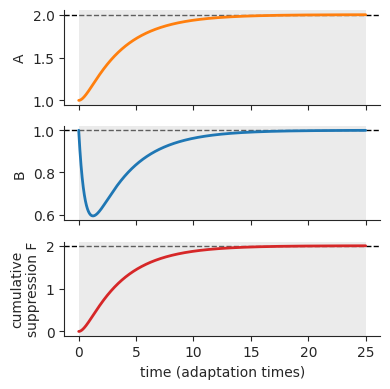

In [10]:
sim_const = simulate_ab([(u_min, 25.0)])
F_inf = (1 / u_min - 1) / (t_relax(q) * q)
print(f'F_inf: simulated {sim_const["F"][-1]:.4f}, analytic {F_inf:.4f}')
print(f'one-off drop rho*alpha*F_inf at rho={rho_fig4}: {rho_fig4 * alpha * F_inf:.2f} e-folds')

fig, axs = plt.subplots(3, 1, figsize=(4, 4), sharex=True)
axs[0].plot(sim_const['t'], sim_const['A'], color='C1', lw=2)
axs[0].axhline(1 / u_min, color='k', ls='--', lw=1, zorder=-1)
axs[0].set_ylabel('A')
axs[1].plot(sim_const['t'], sim_const['B'], color='C0', lw=2)
axs[1].axhline(1, color='k', ls='--', lw=1, zorder=-1)
axs[1].set_ylabel('B')
axs[2].plot(sim_const['t'], sim_const['F'], color='C3', lw=2)
axs[2].axhline(F_inf, color='k', ls='--', lw=1, zorder=-1)
axs[2].set_ylabel('cumulative\nsuppression F')
axs[2].set_xlabel('time (adaptation times)')
for ax in axs:
    shade_on(ax, sim_const)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## 2. One treatment cycle for different $\rho$

Steady state (drug off) → on-treatment for $T_{on}$ → off-treatment for $T_{off}$. Time is in adaptation times, so $A$ and $B$ are the same in every plot. Only $\log C$ changes with $\rho$:
- during treatment it falls at $\rho(\alpha f - 1)$;
- during the holiday it regrows at up to $\rho$.

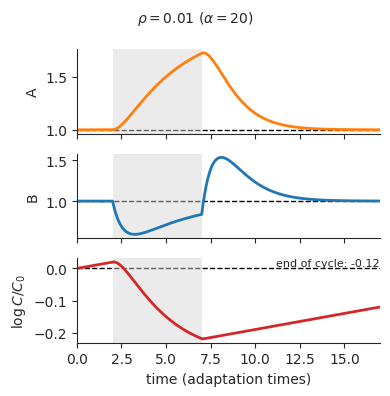

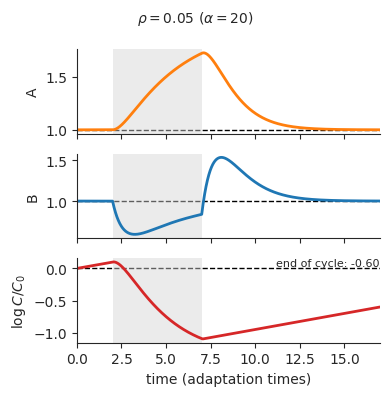

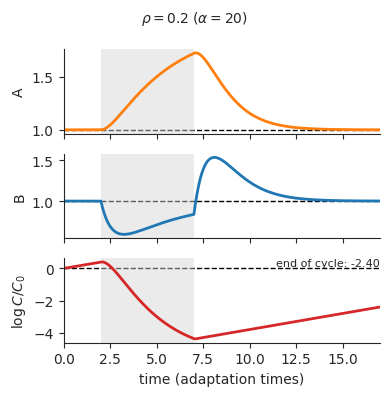

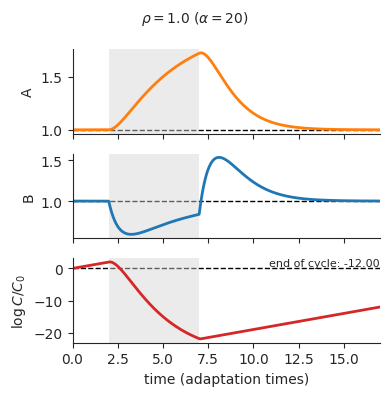

In [11]:
T_pre = 2.0    # steady state before treatment
T_on  = 5.0
T_off = 10.0
rhos  = [0.01, 0.05, 0.2, 1.0]

sim_cycle = simulate_ab([(u_max, T_pre), (u_min, T_on), (u_max, T_off)])

for rho in rhos:
    logC = log_C(sim_cycle, rho)

    fig, axs = plt.subplots(3, 1, figsize=(4, 4), sharex=True)

    ax = axs[0]
    ax.plot(sim_cycle['t'], sim_cycle['A'], color='C1', lw=2)
    ax.axhline(1, color='k', ls='--', lw=1, zorder=-1)
    ax.set_ylabel('A')

    ax = axs[1]
    ax.plot(sim_cycle['t'], sim_cycle['B'], color='C0', lw=2)
    ax.axhline(1, color='k', ls='--', lw=1, zorder=-1)
    ax.set_ylabel('B')

    ax = axs[2]
    ax.plot(sim_cycle['t'], logC, color='C3', lw=2)
    ax.axhline(0, color='k', ls='--', lw=1, zorder=-1)
    ax.set_ylabel(r'$\log C/C_0$')
    ax.set_xlabel('time (adaptation times)')
    ax.text(1.0, 1.0, f'end of cycle: {logC[-1]:+.2f}', transform=ax.transAxes,
            ha='right', va='top', fontsize=8)

    for ax in axs:
        shade_on(ax, sim_cycle)
        ax.set_xlim(0, sim_cycle['t'][-1])
        sns.despine(ax=ax)

    fig.suptitle(fr'$\rho={rho}$ ($\alpha={alpha:g}$)', fontsize=10)
    plt.tight_layout()
    plt.show()

## 3. Does $\alpha$ alone decide success? The threshold $\alpha^*(\rho)$

Over a horizon $\hat T$ (in adaptation times), $\log C(\hat T) = \rho\,[\hat T - \alpha F(\hat T)] < 0$ if and only if

$$\alpha > \alpha^* = \frac{\hat T}{F(\hat T)}$$

The threshold depends on $q$, $u_{\min}$, the schedule and the horizon, not only on $\alpha$. If the horizon is fixed in **adaptation** time, $\rho$ drops out. Clinically, the horizon is fixed in **tumor** time: $H$ untreated tumor e-folds, i.e. $\hat T = H/\rho$. Then

$$\alpha^*(\rho) = \frac{H/\rho}{F(H/\rho)}$$

and $\rho$ enters through the horizon.

- **Constant therapy** (long horizon): $F \to F_\infty$, so $\alpha^* \approx H/(\rho F_\infty)$. Success needs a fast tumor or an enormous $\alpha$.
- **Reset therapy**, small $\rho$ (many cycles): $\alpha^* \to 1/\langle f\rangle_{\text{periodic}}$, independent of $\rho$.
- **Both**, large $\rho$: the horizon is short in adaptation time. The fresh first-dose response lowers $\alpha^*$. When $\hat T$ is shorter than B's response time, $\alpha^*$ rises again because the drug has not taken effect.

Because the schedule's prefix is the same for every horizon, one long simulation per strategy gives $F(\hat T)$ for all $\rho$ at once.

In [ ]:
H = 5.0                               # horizon in untreated tumor e-folds
T_on_reset, T_off_reset = 4.7, 3.2    # best periodic schedule at q=0.25, u_min=0.5 (from a T_on x T_off sweep)
rhos_star = np.logspace(-2.5, 1.5, 200)
T_hats = H / rhos_star                # horizon in adaptation times for each rho

strategies = {
    'constant': ([(u_min, T_hats.max())], CONST_COLOR),
    'reset':    (on_off_schedule(T_on_reset, T_off_reset, T_hats.max()), RESET_COLOR),
}

alpha_star = {}
for name, (segments, _) in strategies.items():
    sim = simulate_ab(segments, n_points=400000)   # fine grid: short horizons (large rho) need resolution
    alpha_star[name] = T_hats / np.interp(T_hats, sim['t'], sim['F'])

alpha_star_periodic = 1 / periodic_suppression(T_on_reset, T_off_reset)
F_inf = (1 / u_min - 1) / (t_relax(q) * q)

for r in [0.01, 0.05, 0.3, 1.0, 3.0]:
    i = np.argmin(abs(rhos_star - r))
    print(f'rho={r:5.2f}: alpha* constant={alpha_star["constant"][i]:7.1f}, reset={alpha_star["reset"][i]:5.2f}')
print(f'reset periodic limit 1/<f> = {alpha_star_periodic:.2f}')

fig, ax = plt.subplots(figsize=(4.5, 3.5))
for name, (_, color) in strategies.items():
    ax.plot(rhos_star, alpha_star[name], color=color, lw=2, label=name)
ax.axhline(alpha_star_periodic, color='k', ls=':', lw=1, label=r'reset, periodic limit $1/\langle f\rangle$')
mask = rhos_star <= 1
ax.plot(rhos_star[mask], H / (rhos_star[mask] * F_inf), color='k', ls='--', lw=1,
        label=r'constant, long horizon $H/(\rho F_\infty)$')
ax.axvline(rho_fig4, color='k', lw=0.8, alpha=0.4)
ax.text(rho_fig4, 1.0, ' fig. 4', fontsize=7, va='top', transform=ax.get_xaxis_transform())
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$\rho$ (tumor growth per adaptation time)')
ax.set_ylabel(r'threshold $\alpha^*$' + '\n(tumor shrinks if ' + r'$\alpha > \alpha^*$)')
ax.set_title(fr'fixed tumor horizon $H={H:g}$ e-folds', fontsize=10)
ax.legend(fontsize=7, frameon=False, loc='upper right')
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Reading the plot.** Prototype values at $H=5$:

| $\rho$ | 0.01 | 0.1 | 0.3 | 1 | 3 |
|---|---|---|---|---|---|
| $\alpha^*$ constant | 250 | 25 | 8 | 3.5 | 3.1 |
| $\alpha^*$ reset | 6.6 | 6.2 | 6.1 | 3.6 | 3.1 |

- **Slow tumor ($\rho \ll 1$, timescale separation):** constant therapy needs an impractically large $\alpha$, because tolerance cancels its effect. Reset therapy has a fixed, finite threshold set only by the circuit, the drug and the schedule. This is the regime where cycling is necessary: the AB system recovers during each holiday while the tumor barely regrows.
- **Fast tumor ($\rho \gtrsim 1$):** the first dose acts before tolerance develops, so both strategies have a low threshold. They coincide once the horizon is shorter than one $T_{on}$, and $\alpha^*$ rises again at very large $\rho$, when the horizon is too short for B to respond.
- **So $\alpha$ alone does not decide.** Success requires $\alpha > \alpha^*(q, u_{\min}, \text{schedule}, \rho)$, and $\rho$ matters through the horizon in adaptation time.